Jasper Lim
9117038

Cross-Entropy Regression Algorithm
https://github.com/JasperCLim/LogisticRegressionClassifier_Workshop.git

Group 5 Peer Repository
https://github.com/AlamirConestoga/LogisticRegressionClassifier_Workshop.git

## Binary Classification from Scratch: Binary Cross-Entropy + Gradient Descent

**Goal:** predict student Pass/Fail from hours studied, implementing logistic regression ourselves (NumPy only) with **Binary Cross-Entropy (log-loss)** as the objective and **gradient descent** to train the weights.

The workshop notebook used `scikit-learn` to fit the model and only *evaluated* log-loss. Here we add the missing pieces: **training** and the **gradient** of the loss.

### 1. Mathematical derivation

**Model.** For $N$ samples with feature matrix $X \in \mathbb{R}^{N\times d}$ (a bias column of ones is included), weights $w \in \mathbb{R}^{d}$:

$$ z = Xw, \qquad \hat{y} = \sigma(z) = \frac{1}{1+e^{-z}} $$

**Objective: Binary Cross-Entropy (log-loss)**

$$ J(w) = -\frac{1}{N}\sum_{i=1}^{N}\Big[y_i\log \hat{y}_i + (1-y_i)\log(1-\hat{y}_i)\Big] $$

**Gradient.** For one sample, use the sigmoid derivative $\sigma'(z)=\sigma(z)\,(1-\sigma(z))$ and the chain rule $\frac{\partial J}{\partial w}=\frac{\partial J}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial z}\cdot\frac{\partial z}{\partial w}$:

$$ \frac{\partial J}{\partial \hat y} = -\frac{y}{\hat y} + \frac{1-y}{1-\hat y} = \frac{\hat y - y}{\hat y(1-\hat y)}, \qquad \frac{\partial \hat y}{\partial z} = \hat y(1-\hat y), \qquad \frac{\partial z}{\partial w} = x $$

The $\hat y(1-\hat y)$ terms cancel:

$$ \frac{\partial J}{\partial w} = (\hat y - y)\,x $$

Averaging over all samples gives the **vectorized gradient**:

$$ \nabla_w J = \frac{1}{N} X^{\top}(\hat{y} - y) $$

**Gradient descent update** with learning rate $\alpha$:

$$ w \leftarrow w - \alpha\,\nabla_w J $$

Because $J$ is convex in $w$, gradient descent converges toward the global minimum (given a suitable $\alpha$).

### 2. Algorithmic steps

1. Build $X$ (add a bias column) and initialize $w = 0$.
2. **Forward pass:** $z = Xw$, $\hat y = \sigma(z)$.
3. **Loss:** compute the BCE $J(w)$ (clip $\hat y$ to avoid $\log 0$).
4. **Gradient:** $\nabla_w J = \frac{1}{N}X^\top(\hat y - y)$.
5. **Update:** $w \leftarrow w - \alpha \nabla_w J$.
6. Repeat 2-5 for a fixed number of epochs (or until the loss stops improving); record the loss history.
7. **Predict:** class 1 if $\hat y \ge 0.5$, else class 0.

### 3. Vectorized implementation

Data and imports (same hours-studied / pass-fail data as the workshop).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

hours_studied = np.array([0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5, 2.75, 3, 3.25, 3.5, 3.75, 4, 4.25, 4.5, 4.75, 5])
pass_fail = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1])

# Design matrix with a bias column of ones: shape (N, 2)
X = np.column_stack([np.ones_like(hours_studied), hours_studied])
y = pass_fail
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (19, 2) | y shape: (19,)


**Sigmoid and Binary Cross-Entropy (the objective).**

In [2]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def binary_cross_entropy(y_true, y_prob, eps=1e-15):
    y_prob = np.clip(y_prob, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))

**Gradient of the BCE** - the vectorized form $\frac{1}{N}X^\top(\hat y - y)$ derived above.

In [3]:
def bce_gradient(X, y_true, w):
    y_prob = sigmoid(X @ w)
    return X.T @ (y_prob - y_true) / len(y_true)

**Gradient check.** Before trusting the analytic gradient, compare it with a numerical (central finite-difference) gradient.

In [4]:
def numerical_gradient(X, y_true, w, h=1e-6):
    grad = np.zeros_like(w)
    for j in range(len(w)):
        step = np.zeros_like(w)
        step[j] = h
        grad[j] = (binary_cross_entropy(y_true, sigmoid(X @ (w + step)))
                   - binary_cross_entropy(y_true, sigmoid(X @ (w - step)))) / (2 * h)
    return grad


w_test = np.array([-1.0, 0.5])
analytic = bce_gradient(X, y, w_test)
numeric = numerical_gradient(X, y, w_test)
print("Analytic :", analytic)
print("Numerical:", numeric)
print("Max abs difference:", np.max(np.abs(analytic - numeric)))
assert np.allclose(analytic, numeric, atol=1e-6)

Analytic : [ 0.10972735 -0.03768164]
Numerical: [ 0.10972735 -0.03768164]
Max abs difference: 7.44686048936849e-11


**Training loop (gradient descent).** Each epoch performs the forward pass, loss, gradient, and weight update.

In [5]:
def train(X, y, lr=0.1, epochs=50000):
    w = np.zeros(X.shape[1])
    loss_history = []
    for _ in range(epochs):
        y_prob = sigmoid(X @ w)                        # forward pass
        loss_history.append(binary_cross_entropy(y, y_prob))  # loss
        w -= lr * bce_gradient(X, y, w)                # gradient step
    return w, loss_history


def predict_proba(X, w):
    return sigmoid(X @ w)


def predict(X, w, threshold=0.5):
    return (predict_proba(X, w) >= threshold).astype(int)


w, loss_history = train(X, y, lr=0.1, epochs=50000)
accuracy = np.mean(predict(X, w) == y)
print(f"Learned weights: bias = {w[0]:.4f}, hours = {w[1]:.4f}")
print(f"Initial loss: {loss_history[0]:.4f} | Final loss: {loss_history[-1]:.4f}")
print(f"Training accuracy: {accuracy:.2%}")

Learned weights: bias = -8.5383, hours = 2.9696
Initial loss: 0.6931 | Final loss: 0.2321
Training accuracy: 89.47%


**Visualizing training and the fitted model.** The loss decreases monotonically as gradient descent proceeds, and the learned S-curve separates fails from passes around the 0.5 threshold.

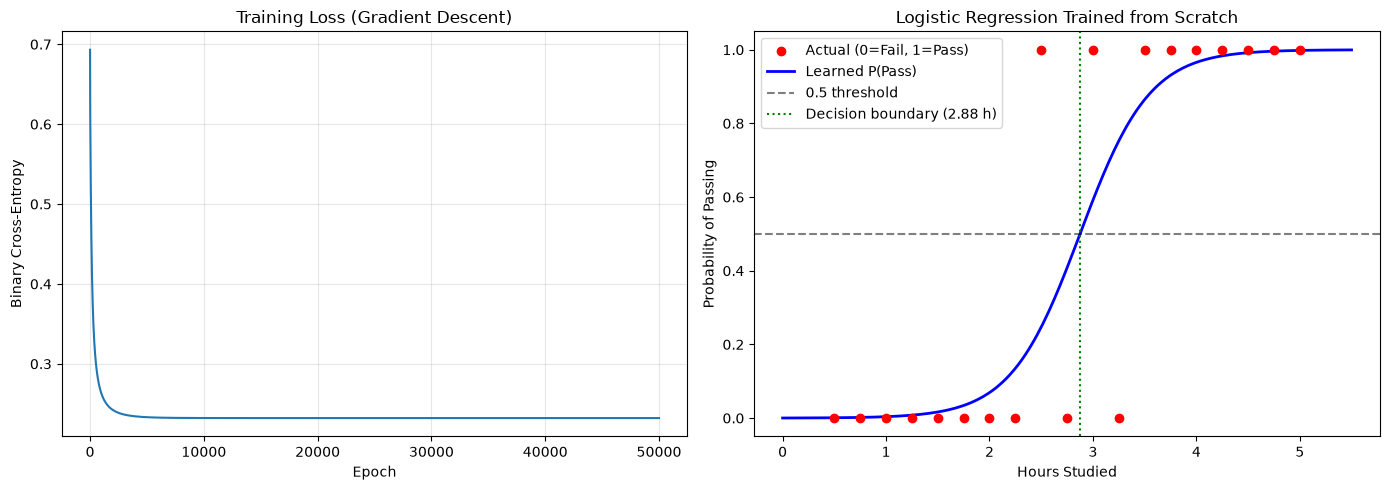

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(loss_history, color="tab:blue")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Binary Cross-Entropy")
ax1.set_title("Training Loss (Gradient Descent)")
ax1.grid(True, alpha=0.3)

grid = np.linspace(0, 5.5, 200)
curve = predict_proba(np.column_stack([np.ones_like(grid), grid]), w)
ax2.scatter(hours_studied, pass_fail, color="red", zorder=3, label="Actual (0=Fail, 1=Pass)")
ax2.plot(grid, curve, color="blue", lw=2, label="Learned P(Pass)")
ax2.axhline(0.5, color="k", ls="--", alpha=0.5, label="0.5 threshold")
boundary = -w[0] / w[1]
ax2.axvline(boundary, color="green", ls=":", label=f"Decision boundary ({boundary:.2f} h)")
ax2.set_xlabel("Hours Studied")
ax2.set_ylabel("Probability of Passing")
ax2.set_title("Logistic Regression Trained from Scratch")
ax2.legend()
plt.tight_layout()
plt.show()

**Sanity check against `scikit-learn`** (unregularized, so the solutions should be very close).

In [7]:
from sklearn.linear_model import LogisticRegression

sk = LogisticRegression(C=np.inf).fit(hours_studied.reshape(-1, 1), pass_fail)
print(f"From scratch : bias = {w[0]:.3f}, hours = {w[1]:.3f}, loss = {loss_history[-1]:.4f}")
print(f"scikit-learn : bias = {sk.intercept_[0]:.3f}, hours = {sk.coef_[0][0]:.3f}, "
      f"loss = {binary_cross_entropy(y, sk.predict_proba(hours_studied.reshape(-1, 1))[:, 1]):.4f}")

From scratch : bias = -8.538, hours = 2.970, loss = 0.2321
scikit-learn : bias = -8.540, hours = 2.970, loss = 0.2321


## Talking Points

1. **The gradient is the key addition.** For BCE with a sigmoid output, the chain rule collapses to $\nabla_w J = \frac{1}{N}X^\top(\hat y - y)$ because the $\hat y(1-\hat y)$ terms cancel. The code is one vectorized line (`X.T @ (y_prob - y_true) / N`), and we verified it against a numerical finite-difference gradient.

2. **Training = repeated forward pass, loss, gradient, update.** The `train` loop starts at `w = 0` and applies `w -= lr * gradient`. The recorded loss falls every epoch because BCE is convex, and the learning rate controls the speed and stability of convergence.

3. **Numerical stability and validation.** Clipping probabilities in `binary_cross_entropy` avoids `log(0)`. The from-scratch weights and loss closely match `scikit-learn`'s unregularized `LogisticRegression`, and the 0.5 threshold gives the decision boundary $-w_0/w_1$ hours.

## Peer Review Talking Points


1. **Strong verification of the loss.** The peer implements `binary_cross_entropy` with `np.clip`, checks it against a hand-calculated example with an `assert`, and demonstrates edge cases (confident mistake vs. confident correct vs. random guess). This makes the objective function easy to trust and understand.

2. **Clear, simple training loop.** The peer uses scalar `w` and `b` with `dw = mean((p - y) * x)` and `db = mean(p - y)`, which is easy to read for one feature. It reaches the same 89.47% accuracy, but 1000 epochs at a learning rate of 0.1 stops at a loss of 0.2595, not yet at the minimum (about 0.232). Our version uses a matrix `X` with a bias column, so it extends to more features, and it trains longer.

3. **Question for the peer: how do you know the gradient is right?** The derivation of $p - y$ is explained well, but the code never checks the gradient numerically, and convergence is only judged by the printed loss. A finite-difference gradient check or a comparison with `scikit-learn` would confirm correctness.